In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df=pd.read_csv("./data/creditcard.csv")
print(f"Dataframe Shape: {df.shape}")

Dataframe Shape: (284807, 31)


In [8]:
# PHASE 1: DQ Check (not running the open sourced agent again)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [9]:
#verifies that all columns are numeric
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [10]:
#checking if columns have any null values:
df.isna().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [11]:
#checking for duplicates
df.duplicated().sum()

np.int64(1081)

In [12]:
#dropping duplicates
df=df.drop_duplicates(keep='first')   #preserve the original transaction record while stripping away any accidental duplicate system logs that followed it

In [13]:
df.shape    #283726+1081=284807     therefore confirmed that duplicates were dropped

(283726, 31)

In [14]:
df.duplicated().sum()   #sanity check

np.int64(0)

In [15]:
#PHASE 2: Univariate Analysis

##Target Variables
df['Class'].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

In [16]:
#displaying percentages of each output
df['Class'].value_counts(normalize=True)*100        

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64

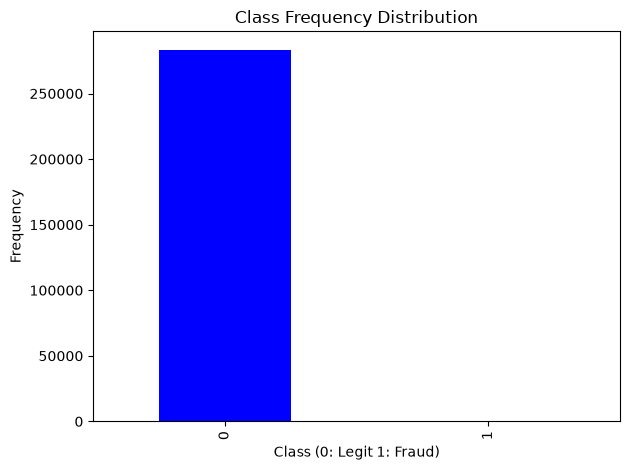

In [17]:
#visualizing it
df['Class'].value_counts().plot(kind='bar', title='Class Frequency Distribution', color=['blue', 'red'])
plt.xlabel('Class (0: Legit 1: Fraud)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [18]:
##Features
df[['V1', 'V2', 'V3']].corr

<bound method DataFrame.corr of                V1         V2        V3
0       -1.359807  -0.072781  2.536347
1        1.191857   0.266151  0.166480
2       -1.358354  -1.340163  1.773209
3       -0.966272  -0.185226  1.792993
4       -1.158233   0.877737  1.548718
...           ...        ...       ...
284802 -11.881118  10.071785 -9.834783
284803  -0.732789  -0.055080  2.035030
284804   1.919565  -0.301254 -3.249640
284805  -0.240440   0.530483  0.702510
284806  -0.533413  -0.189733  0.703337

[283726 rows x 3 columns]>

Verifying the PCA transformation for ALL the features:

-Dataset claims that V1 to V28 are Principal Components resulting from a PCA transformation. 

Why is it that way?
 Because credit card information is proprietary and if non numeric cols are represented numerically using PCA, it hides sensitive information.

-Our goal rn is to ensure that PCA was actually performed properly. 

-So we look for 3 signals: Zero Mean, Decreasing Variance from V1 to V28 & Zero Correlation


In [19]:
#preparing list of V columns:
v_cols=[]
for i in range(1, 29):
    v_cols.append(f'V{i}')

df[v_cols].describe().T     #.T inverts rows and cols

,count,mean,std,min,25%,50%,75%,max
V1,283726.0,0.005917,1.948026,-56.407510,-0.915951,0.020384,1.316068,2.454930
V2,283726.0,-0.004135,1.646703,-72.715728,-0.600321,0.063949,0.800283,22.057729
V3,283726.0,0.001613,1.508682,-48.325589,-0.889682,0.179963,1.026960,9.382558
V4,283726.0,-0.002966,1.414184,-5.683171,-0.850134,-0.022248,0.739647,16.875344
V5,283726.0,0.001828,1.377008,-113.743307,-0.689830,-0.053468,0.612218,34.801666
V6,283726.0,-0.001139,1.331931,-26.160506,-0.769031,-0.275168,0.396792,73.301626
V7,283726.0,0.001801,1.227664,-43.557242,-0.552509,0.040859,0.570474,120.589494
V8,283726.0,-0.000854,1.179054,-73.216718,-0.208828,0.021898,0.325704,20.007208
V9,283726.0,-0.001596,1.095492,-13.434066,-0.644221,-0.052596,0.595977,15.594995
V10,283726.0,-0.001441,1.076407,-24.588262,-0.535578,-0.093237,0.453619,23.745136


In [20]:
#Zero mean
df[v_cols].mean()
#therefore all of them are very very close to zero. 
#they won't be exactly zero right now as we removed duplicates

V1     0.005917
V2    -0.004135
V3     0.001613
V4    -0.002966
V5     0.001828
V6    -0.001139
V7     0.001801
V8    -0.000854
V9    -0.001596
V10   -0.001441
V11    0.000202
V12   -0.000715
V13    0.000603
V14    0.000252
V15    0.001043
V16    0.001162
V17    0.000170
V18    0.001515
V19   -0.000264
V20    0.000187
V21   -0.000371
V22   -0.000015
V23    0.000198
V24    0.000214
V25   -0.000232
V26    0.000149
V27    0.001763
V28    0.000547
dtype: float64

In [21]:
#Decreasing variance (std^2)
df[v_cols].std()    #gradually decreasing

V1     1.948026
V2     1.646703
V3     1.508682
V4     1.414184
V5     1.377008
V6     1.331931
V7     1.227664
V8     1.179054
V9     1.095492
V10    1.076407
V11    1.018720
V12    0.994674
V13    0.995430
V14    0.952215
V15    0.914894
V16    0.873696
V17    0.842507
V18    0.837378
V19    0.813379
V20    0.769984
V21    0.723909
V22    0.724550
V23    0.623702
V24    0.605627
V25    0.521220
V26    0.482053
V27    0.395744
V28    0.328027
dtype: float64

In [22]:
#Zero correlation
df[v_cols].corr()   #the diagonals must be 1 and everything else 0 as Vi and Vi ka correlation will always be 1 but the other combinations must not correlate to one another

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
V1,1.000000,0.006875,-0.008112,0.002257,-0.007036,0.000413,-0.009173,-0.001168,0.001828,0.000815,...,0.000919,-0.001393,0.002818,-0.001436,-0.001330,-0.000723,-0.000222,-0.000684,-0.015706,-0.004861
V2,0.006875,1.000000,0.005278,-0.001495,0.005210,-0.000594,0.007425,0.002899,-0.000274,0.000620,...,-0.000358,-0.001287,-0.004897,0.001237,-0.003855,0.000701,-0.001569,0.000253,0.007555,0.001611
V3,-0.008112,0.005278,1.000000,0.002829,-0.006879,-0.001511,-0.011721,-0.001815,-0.003579,-0.009632,...,-0.000016,-0.002269,0.003500,-0.000275,0.000449,-0.000072,0.000425,-0.000094,-0.007051,-0.000134
V4,0.002257,-0.001495,0.002829,1.000000,0.001744,-0.000880,0.004657,0.000890,0.002154,0.002753,...,-0.000560,0.000318,-0.001034,0.000115,0.000732,-0.000120,0.000162,0.000777,0.001322,0.000231
V5,-0.007036,0.005210,-0.006879,0.001744,1.000000,-0.000938,-0.008709,0.001430,-0.001213,-0.006050,...,0.000436,-0.001185,0.001622,-0.000559,0.001183,0.000198,0.000069,0.000390,-0.005798,-0.000820
V6,0.000413,-0.000594,-0.001511,-0.000880,-0.000938,1.000000,0.000436,0.003036,-0.000734,-0.002180,...,0.000106,-0.000181,-0.002134,0.001104,-0.000755,0.001202,0.000697,-0.000028,0.000289,0.000925
V7,-0.009173,0.007425,-0.011721,0.004657,-0.008709,0.000436,1.000000,-0.006419,-0.004921,-0.013617,...,0.000846,-0.001192,0.009010,-0.002280,0.003303,-0.000384,-0.000072,0.000624,-0.004537,0.001657
V8,-0.001168,0.002899,-0.001815,0.000890,0.001430,0.003036,-0.006419,1.000000,0.001038,0.000481,...,-0.000626,0.000271,0.018892,-0.006156,0.004994,0.000113,0.000011,-0.001407,0.000613,-0.000099
V9,0.001828,-0.000274,-0.003579,0.002154,-0.001213,-0.000734,-0.004921,0.001038,1.000000,-0.012613,...,0.000247,-0.001838,0.000679,0.000785,0.000677,-0.000103,-0.000275,0.001253,0.008221,0.005591
V10,0.000815,0.000620,-0.009632,0.002753,-0.006050,-0.002180,-0.013617,0.000481,-0.012613,1.000000,...,0.001067,-0.004448,0.003777,-0.000481,0.001917,0.000154,-0.000565,0.001089,0.010769,0.009159


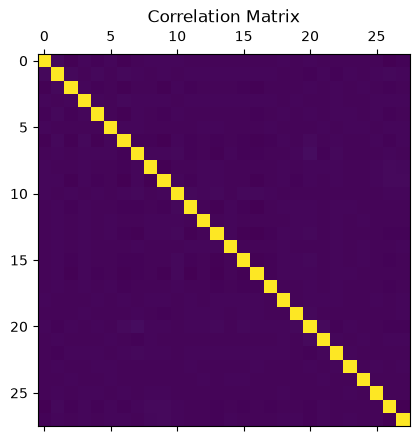

Total correlation sum (Should be around 28): 29.74


In [23]:
#visual check 
plt.matshow(df[v_cols].corr())
plt.title("Correlation Matrix")
plt.show()

#Mathematical check
#In a perfect PCA dataset, a column only correlates with itself (value = 1).
#Since we have 28 columns, the absolute sum of the ENTIRE correlation matrix should be exactly 28.
total_correlation = df[v_cols].corr().abs().sum().sum()

print(f"Total correlation sum (Should be around 28): {total_correlation:.2f}") #its not exactly 28 because we removed the duplicates


In [24]:
#now we perform our univariate analysis on the features
v_stats=df[v_cols].describe().T[['mean', 'max', 'min', 'std']]

In [25]:
#Calculate how extreme the min and max values are in terms of Standard Deviations
v_stats['z_score_min']=(v_stats['min']-v_stats['mean'])/v_stats['std']
v_stats['z_score_max']=(v_stats['max']-v_stats['mean'])/v_stats['std']

In [26]:
# Find the absolute most extreme outlier for each column
v_stats['most_extreme']=v_stats[['z_score_min', 'z_score_max']].abs().max(axis=1)

In [27]:
display(v_stats.sort_values('most_extreme', ascending=False))

,mean,max,min,std,z_score_min,z_score_max,most_extreme
V28,0.000547,33.847808,-15.430084,0.328027,-47.040792,103.184498,103.184498
V7,0.001801,120.589494,-43.557242,1.227664,-35.481244,98.225332,98.225332
V5,0.001828,34.801666,-113.743307,1.377008,-82.603087,25.272062,82.603087
V27,0.001763,31.612198,-22.565679,0.395744,-57.025373,79.875992,79.875992
V23,0.000198,22.528412,-44.807735,0.623702,-71.841851,36.120134,71.841851
V20,0.000187,39.420904,-54.497720,0.769984,-70.777952,51.196784,70.777952
V8,-0.000854,20.007208,-73.216718,1.179054,-62.097103,16.969584,62.097103
V6,-0.001139,73.301626,-26.160506,1.331931,-19.640187,55.034974,55.034974
V21,-0.000371,27.202839,-34.830382,0.723909,-48.113774,37.578198,48.113774
V2,-0.004135,22.057729,-72.715728,1.646703,-44.155864,13.397598,44.155864


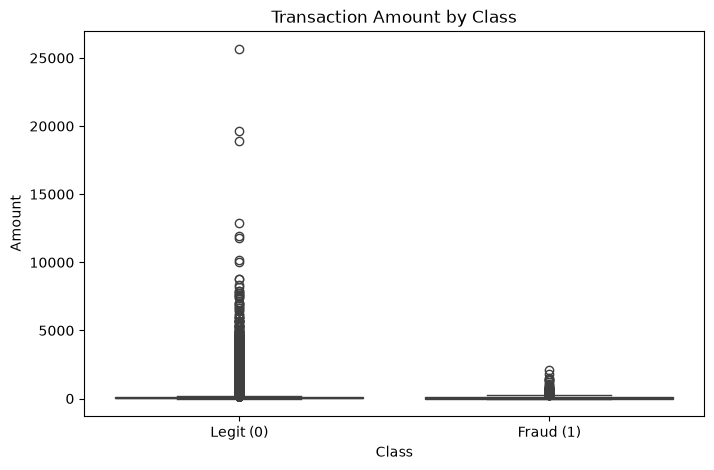

In [28]:
#PHASE 3: Bivariate & Multivariate Analysis

##Bivariate Analysis

### Lets check if Amount plays a role in determining the Classes 
plt.figure(figsize=(8, 5))
sns.boxplot(x='Class', y='Amount', data=df)
plt.title('Transaction Amount by Class')
plt.xticks([0, 1], ['Legit (0)', 'Fraud (1)'])
plt.show()

In [29]:
#the boxes are so squished that you cant even tell they exist. So lets try to understand why this is the case
df['Amount'].describe()

count    283726.000000
mean         88.472687
std         250.399437
min           0.000000
25%           5.600000
50%          22.000000
75%          77.510000
max       25691.160000
Name: Amount, dtype: float64

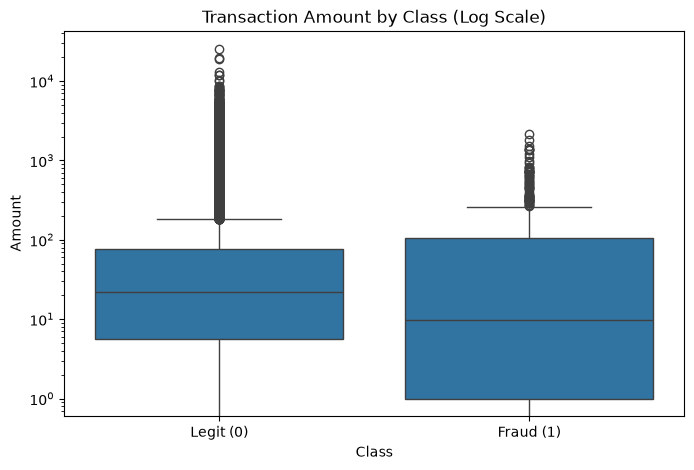

In [30]:
#therefore in order to accomodate the outliers above 20k Amount, everything below the box plot (about 75%) got squished into almost nothing under the respective Classes
#so now we use a log transformation on the data
plt.figure(figsize=(8, 5))
sns.boxplot(x='Class', y='Amount', data=df)
plt.yscale('log') # This fixes the squishing!
plt.title('Transaction Amount by Class (Log Scale)')
plt.xticks([0, 1], ['Legit (0)', 'Fraud (1)'])
plt.show()


now the box plot is clearly visible.
observations:

-median & 75 percentile are similar (massive overlap): 
  An ML algorithm will struggle here because if it sees a transaction in this overlapping region, 
  it won't be able to differentiate between the two classes using Amount as the parameter.

-Legit has bigger outliers:
  This means that huge transactions are more linked to Legit than Fraud.

-25% percentile is much lower in fraud than legit:
  This means transactions involving lesser amounts are more linked to Fraud than Legit. 
  Maybe fraudsters test out their strategies with lesser amounts of money initially to minimize their losses.

FINAL CONCLUSION for Amount:
While there are tiny nuances, the massive overlap between the two boxes means that Amount is a weak standalone predictor. 
So we cannot rely on it heavily to catch fraud.

In [31]:
### Evaluating PCA features (V1-28):
#Linear correlation can be misleading. Instead, we will calculate the Standardized Median Difference (Effect Size). 
#This tells us exactly how far apart the "center" of the Fraud data is from the "center" of the Legit data.

In [32]:
#Calculate median for each class for the V columns
medians=df.groupby('Class')[v_cols].median()
print(medians)


             V1        V2        V3        V4        V5        V6        V7  \
Class                                                                         
0      0.022562  0.062561  0.182247 -0.024500 -0.052807 -0.274172  0.041664   
1     -2.271755  2.617105 -4.875397  4.100098 -1.372245 -1.420468 -2.902079   

             V8        V9       V10  ...       V19       V20       V21  \
Class                                ...                                 
0      0.021633 -0.051368 -0.092120  ...  0.002737 -0.062507 -0.029798   
1      0.617738 -2.099049 -4.466284  ...  0.647709  0.285559  0.573898   

            V22       V23       V24       V25       V26       V27       V28  
Class                                                                        
0      0.006675 -0.011077  0.041115  0.016190 -0.052293  0.001368  0.011238  
1      0.055179 -0.075034 -0.061263  0.077913  0.012792  0.394682  0.145895  

[2 rows x 28 columns]


In [33]:
#Calculate overall standard deviation
overall_std=df[v_cols].std()
print(overall_std)

V1     1.948026
V2     1.646703
V3     1.508682
V4     1.414184
V5     1.377008
V6     1.331931
V7     1.227664
V8     1.179054
V9     1.095492
V10    1.076407
V11    1.018720
V12    0.994674
V13    0.995430
V14    0.952215
V15    0.914894
V16    0.873696
V17    0.842507
V18    0.837378
V19    0.813379
V20    0.769984
V21    0.723909
V22    0.724550
V23    0.623702
V24    0.605627
V25    0.521220
V26    0.482053
V27    0.395744
V28    0.328027
dtype: float64


In [34]:
#Calculate standardized median difference (Effect Size)
effect_size=((medians.loc[1] - medians.loc[0]) / overall_std)
print(effect_size)

V1    -1.177765
V2     1.551308
V3    -3.352359
V4     2.916592
V5    -0.958192
V6    -0.860627
V7    -2.397841
V8     0.505578
V9    -1.869187
V10   -4.063670
V11    3.494750
V12   -5.607791
V13   -0.050962
V14   -6.975353
V15   -0.096260
V16   -3.858318
V17   -6.044458
V18   -1.691568
V19    0.792954
V20    0.452043
V21    0.833939
V22    0.066944
V23   -0.102544
V24   -0.169045
V25    0.118421
V26    0.135017
V27    0.993859
V28    0.410507
dtype: float64


In [35]:
#Display the features with the strongest absolute separation 
top_separators=effect_size.abs().sort_values(ascending=False).head(8)
print(top_separators)

V14    6.975353
V17    6.044458
V12    5.607791
V10    4.063670
V16    3.858318
V11    3.494750
V3     3.352359
V4     2.916592
dtype: float64


### 3. Visualizing the Best Predictors
Let's visually confirm that our top mathematical separators actually separate the classes well using boxplots.


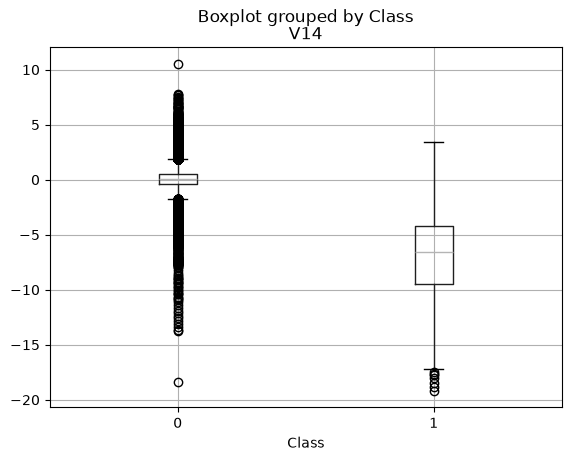

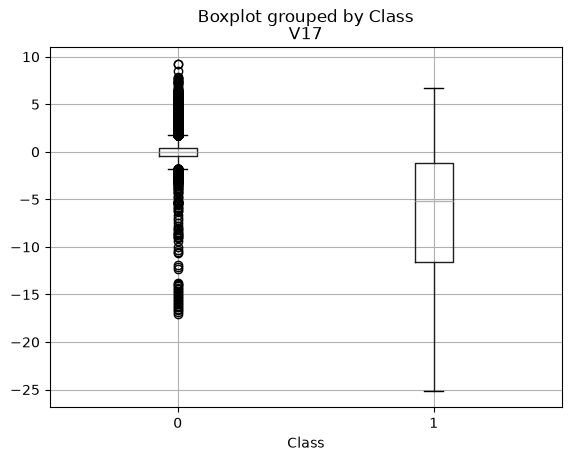

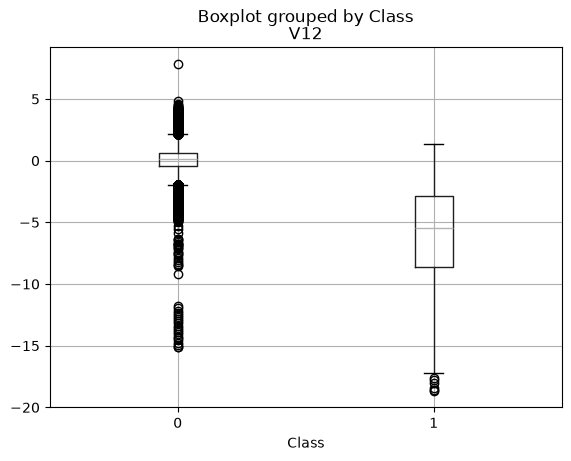

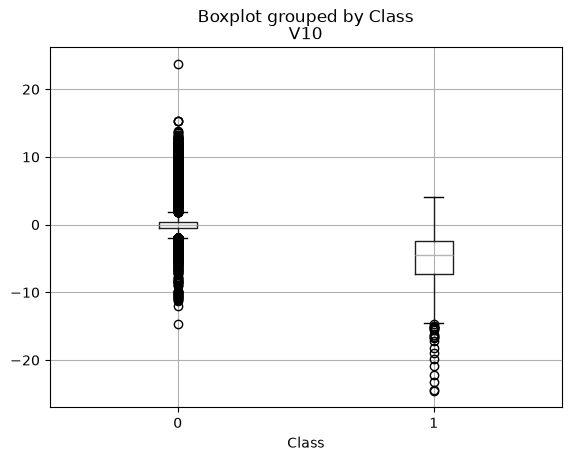

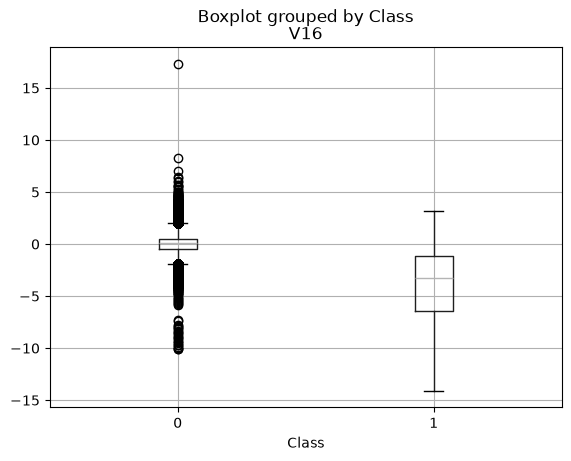

In [36]:
# Loop through the names (index) of the top 4 separators
for col in top_separators.head(5).index:
    df.boxplot(column=col, by='Class')
    plt.show()

**Observation:** Features like `V10`, `V12`, `V14`, `V16` and `V17` show incredible separation. The "box" for Fraud sits almost entirely separated from the "box" for Legit. 

These will be the primary drivers for our machine learning model


In [37]:
feature_corr=df.drop(columns=['Class']).corr()
print(feature_corr)

            Time        V1        V2        V3        V4        V5        V6  \
Time    1.000000  0.117927 -0.010556 -0.422054 -0.105845  0.173223 -0.063279   
V1      0.117927  1.000000  0.006875 -0.008112  0.002257 -0.007036  0.000413   
V2     -0.010556  0.006875  1.000000  0.005278 -0.001495  0.005210 -0.000594   
V3     -0.422054 -0.008112  0.005278  1.000000  0.002829 -0.006879 -0.001511   
V4     -0.105845  0.002257 -0.001495  0.002829  1.000000  0.001744 -0.000880   
V5      0.173223 -0.007036  0.005210 -0.006879  0.001744  1.000000 -0.000938   
V6     -0.063279  0.000413 -0.000594 -0.001511 -0.000880 -0.000938  1.000000   
V7      0.085335 -0.009173  0.007425 -0.011721  0.004657 -0.008709  0.000436   
V8     -0.038203 -0.001168  0.002899 -0.001815  0.000890  0.001430  0.003036   
V9     -0.007861  0.001828 -0.000274 -0.003579  0.002154 -0.001213 -0.000734   
V10     0.031068  0.000815  0.000620 -0.009632  0.002753 -0.006050 -0.002180   
V11    -0.248536  0.001028 -0.000633  0.

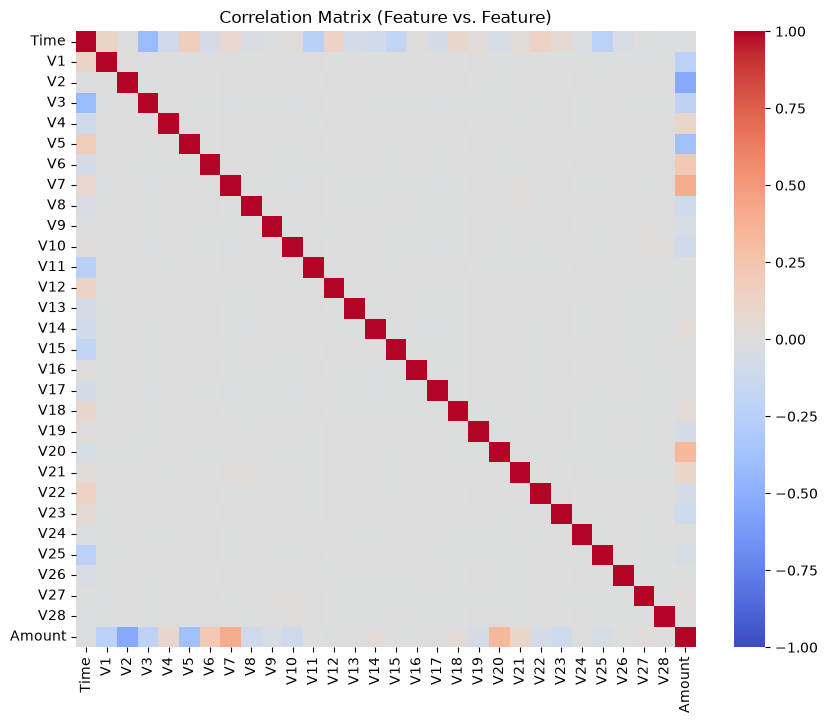

In [38]:
plt.figure(figsize=(10, 8))
sns.heatmap(feature_corr, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation Matrix (Feature vs. Feature)')
plt.show()

Since amount and time didn't undergo PCA, some of their correlation values are above 0. 
However, we cannot see severe amounts of multicollinearity anywhere and can therefore continue with this data for our Logistic Regression model.

In [39]:
#PHASE 4: Feature Engineering

# creating Hour column using the time column
df['Hour']=(df['Time']/3600)%24
df['Hour']=df['Hour'].astype('int')

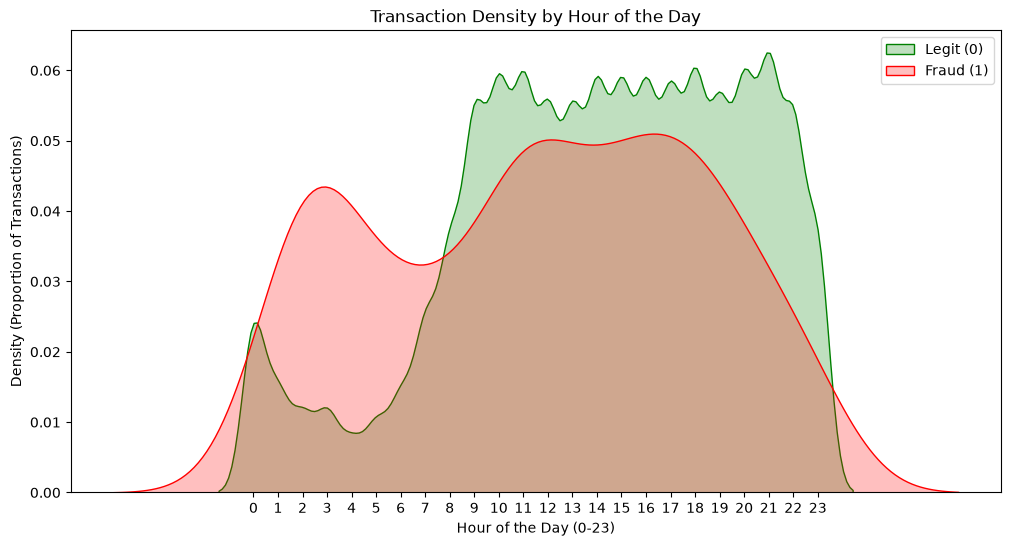

In [40]:
#kdeplot to see the legit vs fraud transactions by hour (kernel density estimate plot)
plt.figure(figsize=(12, 6))
sns.kdeplot(df[df['Class']==0]['Hour'], label='Legit (0)', fill=True, color='green')
sns.kdeplot(df[df['Class']==1]['Hour'], label='Fraud (1)', fill=True, color='red')

plt.title('Transaction Density by Hour of the Day')
plt.xlabel('Hour of the Day (0-23)')
plt.ylabel('Density (Proportion of Transactions)')
plt.xticks(np.arange(0, 24, 1))
plt.legend()
plt.show()

noticed that fraudulent transactions peak around hour 2

In [41]:
#Drop the original Time column cuz we don't want our model getting confused
df=df.drop(columns=['Time'])

--------------------------------------

EXPLORATORY DATA ANALYSIS IS NOW COMPLETE

--------------------------------------

DATA PREPROCESSING: 

a.) test-train-split

b.) scaling

---------------------

In [42]:
from sklearn.model_selection import train_test_split

a.) test-train-split

In [43]:
X=df.drop(columns=['Class'])
y=df['Class']

X_train, X_test, y_train, y_test=train_test_split(
    X, y,
    test_size=0.5,
    shuffle=False
)

b.) scaling

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler

In [45]:
preprocessor=ColumnTransformer(
    transformers=[
        #('name_of_step', Transformer(), ['columns_to_scale'])      
        #Scikit-Learn requires this name just in case you ever need to dig into the machine later and extract this specific step.
        ('scale', RobustScaler(), ['Amount', 'Hour'])   
        #I am creating a step named 'scale', it will use the RobustScaler() tool, and it is only allowed to touch the 'Amount' and 'Hour' columns.
    ],
    remainder='passthrough' #IMPP: tells the machine to leave V1-V28 alone
)

#X_train_scaled_array = preprocessor.fit_transform(X_train)
#X_test_scaled_array  = preprocessor.transform(X_test)

commented out the two lines cuz we don't wanna manually scale it. We wanna allow our preprocessor to do it later on

In [46]:
#ColumnTransformer outputs a raw NumPy array. 

#feature_names=preprocessor.get_feature_names_out()
#X_train=pd.DataFrame(X_train_scaled_array, columns=feature_names)
#X_test=pd.DataFrame(X_test_scaled_array, columns=feature_names)

Scikit-learn tools like ColumnTransformer strip away all the column names (like 'V1', 'Amount', etc) and the row numbers.

It spits out a raw Numpy array, which is just an anonymous block of numbers. We can't see which column is which.

While the ML algorithms are perfectly capable of training on this array, we still need the col names and row numbers in the explainability (SHAP) phase of our project.

If we don't have col names, SHAP will just say "Feature 0 is most important".

Instead, we want it to say "Hour is the most important". (example)

----------

DATA PREPROCESSING IS NOW COMPLETE

----------------

**MODEL TRAINING AND ADVANCED VALIDATION**

In [47]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

**Building the pipelines:**

a.) logistic regression:

In [48]:
logistic_pipeline=Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(random_state=42, max_iter=1000, class_weight="balanced"))
])

random_state=42 ensures that everytime we run our algorithm, it starts at a fixed point and consistently gives us the same output

max_iter=1000 tells the model that it can take upto 1000 steps to find the correct answer in each prediction.
Keeping this high for large datasets is essential or LR will throw a convergence error

class_weight="balanced" is used for imbalanced datasets. It tells the algorithm that for every misclassified fraud row, penalize yourself way more than you would with a
misclassified legit row.
this is done by assigning larger weights to fraud cases than compared to legit. Algo chooses the weight automatically

b.) xgBoost:

In [49]:
xgboost_pipeline=Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(random_state=42, scale_pos_weight=576))
])

scale_pos_weight = number of negative cases / number of positive cases

therefore here, = legit_cases / fraud_cases = 144000 / 250 = 576

because we are tryna detect fraud with the algo

so now, the weight of fraud 576x that of legit cases.

**Evaluating the models:**

In [50]:
from sklearn.metrics import (
    average_precision_score, roc_auc_score, 
    precision_score, recall_score, f1_score, confusion_matrix
)

In [51]:

def evaluate_model(pipeline, model_name, X_train, y_train, X_test, y_test):
    #training the model
    pipeline.fit(X_train, y_train)

    #predict on the test set:
    test_probabilities=pipeline.predict_proba(X_test)[:, 1]

    test_predictions=pipeline.predict(X_test)

    print(f"{model_name} (Test Results)")
    print(f"PR-AUC:    {average_precision_score(y_test, test_probabilities)}")
    print(f"ROC-AUC:   {roc_auc_score(y_test, test_probabilities):.4f}")
    print(f"Precision: {precision_score(y_test, test_predictions):.4f}")
    print(f"Recall:    {recall_score(y_test, test_predictions):.4f}")
    print(f"F1 Score:  {f1_score(y_test, test_predictions):.4f}")

    print("\nConfusion Matrix: ")
    print(confusion_matrix(y_test, test_predictions))

why do we fit X_train and y_train to our pipeline and not fit and transform?

When you run pipeline.fit(X_train), the pipeline is incredibly smart. 
Under the hood, it automatically runs .fit_transform() on the preprocessor (scaling the data), and then takes that newly scaled data and passes it to XGBoost and runs .fit().

You literally cannot call .fit_transform() on the entire pipeline because the final step is an ML algorithm. 

Algorithms do not "transform" data (they don't spit out new columns of data). They just study it (fit) and make decisions (predict).

**test_probabilities=pipeline.predict_proba(X_test)[:, 1]**

Explanation: predict_proba asks the model to output a percentage or probability instead of a hard Yes or No. 
By default, Scikit-Learn outputs a 2D array with 2 columns: a.) P(Legit) b.) P(Fraud).

Since we are only concerned with the fraud probabilities, we slice it like [:1].
It returns all the rows with their respective P(Fraud)


**test_predictions=pipeline.predict(X_test)**

Explanation: Under the hood right now, Scikit-learn just uses a blind 50% cutoff line. If the probability from the previous step was > 0.50, it outputs 1 & if < 0.50, outputs 0.

Why are we using PR-AUC, ROC-AUC, Precision, Recall, F1 score and confusion matrix?
What do they represent?

**-Confusion Matrix:** helps us find TN, TP, FP, FN.

**-Precision:** Out of the total of positive cases you flagged, how many were truly positive. **Precision = TP/(TP+FP)**

**-Recall:** Out of all the actual positive cases that were present, how many positive cases were actually found. **Recall = TP/(TP+FN)**

**-F1 Score:** Say if I have two models. A has high recall and low precision and B is vice-versa. How do I know which is better? Using F1 score.
**F1 score = 2RP/(R+P)**

**-PR-AUC:** Precision Recall-Area Under Curve. The Holy Grail for **imbalanced data**. .predict() only tests the model at a 50% cutoff line. PR-AUC tests the model at every single possible cutoff line (1%, 15%, 99%) and averages the Precision and Recall across all of them. **If PR-AUC is high, it means the model is mathematically brilliant at separating the classes.**

**-ROC-AUC:** Receiver Operating Characteristic-Area Under Curve. Is used for the same thing as PR-AUC but is terrible for imbalanced data. For instance, we observe that our LR pipeline has a ROC-AUC score of 96% but precision of only 3% two cells down. 

Evaluating Logistic Regression Model:

In [52]:
evaluate_model(
    logistic_pipeline, 
    "Logistic Regression", 
    X_train, y_train, X_test, y_test
)


Logistic Regression (Test Results)
PR-AUC:    0.7691157270263979
ROC-AUC:   0.9658
Precision: 0.0320
Recall:    0.9005
F1 Score:  0.0618

Confusion Matrix: 
[[135908   5744]
 [    21    190]]


Evaluating XGBoost Model:

In [53]:
evaluate_model(
    xgboost_pipeline,
    "XG Boost",
    X_train, y_train, X_test, y_test
)

XG Boost (Test Results)
PR-AUC:    0.7736365390403852
ROC-AUC:   0.9702
Precision: 0.6975
Recall:    0.7867
F1 Score:  0.7394

Confusion Matrix: 
[[141580     72]
 [    45    166]]


**Observations:**

**1.) LR:** Did a good job at catching fraudsters due to high recall value but there's a large number of false positives as indicated by the precision score of 3%.

**2.) XGBoost:** Lower recall value but much higher precision value, so fewer false positives.

Therefore XGBoost is already better than LR. After tuning it should improve even further.

Trying out a Naive Bayes Model:

In [54]:
from sklearn.naive_bayes import GaussianNB

nb_pipeline = Pipeline(steps=[
    ('prep', preprocessor),
    ('clf', GaussianNB())
])

evaluate_model(
    nb_pipeline, 
    "Naive Bayes (Experimental)", 
    X_train, y_train, X_test, y_test
)


Naive Bayes (Experimental) (Test Results)
PR-AUC:    0.06744096990997173
ROC-AUC:   0.9652
Precision: 0.0482
Recall:    0.8246
F1 Score:  0.0911

Confusion Matrix: 
[[138218   3434]
 [    37    174]]


Both Logistic Regression and XGBoost had a PR-AUC of around 0.77. Naive Bayes has 0.06. 

Why? Because PR-AUC measures the quality of the underlying probabilities, not just the final Yes/No decision. 

This mathematically proves that Naive Bayes is spitting out absolute garbage probabilities 

(e.g. telling us it's 99.9% sure a transaction is fraud when it's actually completely innocent). 

If we tried to threshold-tune this model later, it would completely fall apart.

**THEREFORE WE WILL NOT PROCEED WITH THIS MODEL**

How did we decide to use Logistic Regression & XGBoost?

Why not use Naive Bayes, Random Forest, SVMs, KNN or DL/Neural Networks?


-Naive Bayes: Didn't use due to low PR-AUC score

-Random Forest: Here there are a bunch of trees who vote to see if the the transaction is fraudulent or not and accordingly gives an answer. XGBoost is a slightly improved version of this where every new tree learns from the mistakes of the previous one. Therefore we prefer XGBoost over Random Forest.

-SVMs: They are notoriously slow at handling large datasets. 300k rows might take it multiple hours to train, so we dropped it.

-KNN: Poor when a number of features/dimensions are involved. Here there are 30, so it was dropped.

-DL/Neural Networks: Its established that these are better algorithms for text/images/videos than XGBoost. However, XGBoost is far better when it comes to tabular data. Therefore, we prefer this.

We need to show how XGBoost performs better than a baseline model like Logistic Regression.

**THEREFORE WE WILL ONLY USE LOGISTIC REGRESSION AND XGBOOST**

---------

**Cross Validation:**
Measures how well an ML model performs on unseen data while preventing overfitting.

1.)KFold:

We take the Training Set (Day 0), chop it into 5 pieces (folds), train on 4 pieces, and test on the remaining 1 piece. We rotate this until every piece has been the test piece

In [55]:
from sklearn.model_selection import KFold

In [56]:
basic_cv = KFold(n_splits=5, shuffle=True, random_state=42)

fold_stats = []
for fold, (train_idx, val_idx) in enumerate(basic_cv.split(X_train, y_train)):
    fraud_count = y_train.iloc[val_idx].sum()
    total_val_rows = len(val_idx)
    fold_stats.append({
        'Fold': fold + 1, 
        'Frauds in Validation': fraud_count,
        'Total Rows': total_val_rows
    })

In [57]:
print("Standard KFold Results:")
print(pd.DataFrame(fold_stats))

Standard KFold Results:
   Fold  Frauds in Validation  Total Rows
0     1                    61       28373
1     2                    59       28373
2     3                    37       28373
3     4                    50       28372
4     5                    55       28372


Frauds vary from one fold to another significantly, so lets try a different method

2.) Stratified KFold

Around 0.17% of our dataset was fraudulent.

In this method 0.17% is split across 5 folds equally and then we test it the same way as KFold.

In [58]:
from sklearn.model_selection import StratifiedKFold

In [59]:
strat_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

strat_fold_stats = []
for fold, (train_idx, val_idx) in enumerate(strat_cv.split(X_train, y_train)):
    fraud_count = y_train.iloc[val_idx].sum()
    total_val_rows = len(val_idx)
    strat_fold_stats.append({
        'Fold': fold + 1, 
        'Frauds in Validation': fraud_count,
        'Total Rows': total_val_rows
    })

In [60]:
print("StratifiedKFold Results:")
print(pd.DataFrame(strat_fold_stats))

StratifiedKFold Results:
   Fold  Frauds in Validation  Total Rows
0     1                    52       28373
1     2                    53       28373
2     3                    53       28373
3     4                    52       28372
4     5                    52       28372


Frauds appear to be extremely similar in all 5 cases.

But there is a massive flaw. In order to split the fraudulent cases equally across all folds, we had to shuffle the data.

This will cause **Data Leakage** as now that we shuffle, our model uses future transactions to predict past transactions.

So we can't use this cross-validation technique either.

3.) TimeSeriesSplit

Since we have a time-series dataset, preventing data leakage is our absolute priority. So we must sacrifice the perfect 52/53 fraud balance across folds to ensure data leakage doesn't occur. 

TimeSeriesSplit refuses to shuffle the data. Instead, it tests the model by gradually expanding the training window (e.g., train on Monday, test on Tuesday; train on Monday+Tuesday, test on Wednesday), perfectly mimicking how a real-world model learns over time.

In [61]:
from sklearn.model_selection import TimeSeriesSplit

In [62]:
tscv = TimeSeriesSplit(n_splits=5)

ts_fold_stats = []
for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train, y_train)):
    fraud_count = y_train.iloc[val_idx].sum()
    total_val_rows = len(val_idx)
    ts_fold_stats.append({
        'Fold': fold + 1, 
        'Frauds in Validation': fraud_count,
        'Total Rows': total_val_rows
    })

In [63]:
print("TimeSeriesSplit Results:")
print(pd.DataFrame(ts_fold_stats))

TimeSeriesSplit Results:
   Fold  Frauds in Validation  Total Rows
0     1                    58       23643
1     2                    31       23643
2     3                    40       23643
3     4                    23       23643
4     5                    22       23643


Frauds are heavily imbalanced across all 5 folds but its assured to us that there is no Data Leakage.

Both, KFold and StratifiedKFold had the same issue of data leakage and therefore couldn't be used.

Hence we will have to use TimeSeriesSplit for our cross validation.

------

**HYPERPARAMETER TUNING:**

So at this point we have successfully picked our cross validation technique.

Now where is this used? **Hyperparameter tuning**

Why do we need Hyperparameter tuning and what does it do?

Think of hyperparameters as tuning dials that are used the improve our ML algorithm, in this case being **n_estimators, max_depth and learning_rate** for **XGBoost.**

Right now, XGBoost has certain default settings that are designed to be "Fast and Aggressive". They work well on almost anything, but they are highly prone to Overfitting. 
So tuning them in the right way improves the algorithm by reducing its overfitting for example. 

So all in all, understand that while the default settings are good they aren't gonna be optimal for our particular set of data, which is why this phase is absolutely essential.

So anyway, what's been established so far is that different cases are created using different RANDOM combinations of the various hyperparameters involved.

So each of these cases are taken one by one and our run through the obtained 5 folds of TimeSeriesSplit. The average PR-AUC grade is calculated for the case across the 5 folds, and that grade is handed back to the tuner.

The tuner then randomly chooses the next combination of hyperparameters and repeats the process.

After trying all the combinations, the tuner looks at all the grades and picks the combination of hyperparameters having the best grades. 

XGBoost's hyperparameters are then set to these optimal values by the end of it.

How do we know how many combinations to try? cuz they can be infite.

we set a variable **n_iter**, that stands for "number of iterations". This tells the algorithm to generate exactly n_iter number of combinations and run each of those through all the cross validation tracks. Once that's done, the best of the batch is picked out as mentioned earlier.

After some research, I found that in the real world, if you were doing this for JPMorgan and had a massive supercomputer, you would set n_iter=500, go home for the weekend, and let it run for 48 hours to find the perfect combination.

But since we are running this locally on a standard computer, setting it to 10 or 20 ensures it finishes in a few minutes, but still gives us a massive performance boost over the default settings.

So the cross-validation technique is essentially a grading system for each of the combinations.

In [64]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

In [65]:
param_distributions = {
    'model__n_estimators': randint(200, 600),     #number of trees
    'model__max_depth': randint(3, 8),            #how deep the trees can grow
    'model__learning_rate': uniform(0.01, 0.15),  #how deep the trees can grow
    'model__subsample': uniform(0.5, 0.5),        #% of rows used per tree
    'model__colsample_bytree': uniform(0.5, 0.5)  #% of columns used per tree
}

#the hyperparameters must always be named in the following format: [name_of_the_step]__[exact_name_of_the_knob]

# 2. Build the Search Engine
xgboost_search = RandomizedSearchCV(
    estimator=xgboost_pipeline,    #ml pipeline used
    param_distributions=param_distributions,    #hyperparameters used
    n_iter=15,                     #number of combinations 
    scoring='average_precision',   #codeword for pr-auc. tells scikit-learn that it must only judge based on this parameter
    cv=tscv,                       #cross validation technique
    random_state=42,               #for consistent output, set a fixed starting point
    n_jobs=-1,                     #using all cpu cores to make it faster
    verbose=1                      #print out progress (easier to debug)
)

In [66]:
print("Performing Hyperparameter tuning...")
xgboost_search.fit(X_train, y_train)  

Performing Hyperparameter tuning...
Fitting 5 folds for each of 15 candidates, totalling 75 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': <scipy.stats....001340D4F2990>, 'model__learning_rate': <scipy.stats....001340D4C5940>, 'model__max_depth': <scipy.stats....001340D4F2350>, 'model__n_estimators': <scipy.stats....001340D4C57F0>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at

In [67]:
print(f"\nBest Cross-Validation PR-AUC Score: {xgboost_search.best_score_:.4f}")
print("Best Hyperparameters:")
for param, value in xgboost_search.best_params_.items():
    print(f"{param}: {value}")


Best Cross-Validation PR-AUC Score: 0.7831
Best Hyperparameters:
model__colsample_bytree: 0.9711008778424264
model__learning_rate: 0.09449323267683088
model__max_depth: 4
model__n_estimators: 464
model__subsample: 0.5079831261101071


We can clearly see that the PR-AUC score jumped from 0.77 to 0.7831.

So a pretty decent jump was observed. +ve signs.

--------

**Threshold Optimization**

This is the last thing we gotta tune our algorithm for, but it's damn important.

Scikit-Learn assumes that 50% probability is the perfect cutoff line for fraud. But that doesn't mean that thats actually the most optimal cutoff we can use right.

So there's a way to tune this threshold too, and thats what this section deals with.


So we've written a loop that tests every single cutoff line from 1% to 99%, calculates their F1 scores, and keeps tracking the maximum F1 score. 

Whichever specific cutoff line produced that maximum F1 score becomes our new, official Threshold.

For Example:

Test 34% Threshold: We calculate the F1-Score. It gets 0.70.

Test 35% Threshold: We calculate the F1-Score. It gets 0.75.

Test 36% Threshold: We calculate the F1-Score. It gets 0.71.

The loop finishes.

The Maximum F1-Score achieved was 0.75.

The Optimal Threshold (the cutoff line that achieved that score) was 0.35 (35%).

In [68]:
best_xgboost_model = xgboost_search.best_estimator_

#get the probabilities for the training set directly
cross_val_probabilities=best_xgboost_model.predict_proba(X_train)[:, 1]

best_threshold=0.50
best_f1_score=0.0

print("Scanning all possible thresholds...")

for thresh in np.arange(0.01, 1.00, 0.01):
    
    temp_predictions=np.where(cross_val_probabilities >= thresh, 1, 0)
    
    current_f1_score=f1_score(y_train, temp_predictions)
    
    if current_f1_score>best_f1_score:
        best_f1_score=current_f1_score
        best_threshold=thresh   


Scanning all possible thresholds...


In [69]:
print(f"Default 50% Threshold F1-Score: {f1_score(y_train, np.where(cross_val_probabilities >= 0.50, 1, 0)):.4f}")
print(f"Optimal Threshold: {best_threshold:.2f}")
print(f"New Optimal F1-Score: {best_f1_score:.4f}")

Default 50% Threshold F1-Score: 0.9981
Optimal Threshold: 0.57
New Optimal F1-Score: 1.0000


In [70]:
final_test_probabilities = best_xgboost_model.predict_proba(X_test)[:, 1]

optimal_threshold = 0.57
final_test_predictions = np.where(final_test_probabilities >= optimal_threshold, 1, 0)

In [71]:
print("Final XGBoost Model Results After tuning:")
print(f"PR-AUC:    {average_precision_score(y_test, final_test_probabilities):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, final_test_probabilities):.4f}")
print(f"Precision: {precision_score(y_test, final_test_predictions):.4f}")
print(f"Recall:    {recall_score(y_test, final_test_predictions):.4f}")
print(f"F1 Score:  {f1_score(y_test, final_test_predictions):.4f}")

print("\nFinal Confusion Matrix:")
print(confusion_matrix(y_test, final_test_predictions))

Final XGBoost Model Results After tuning:
PR-AUC:    0.7654
ROC-AUC:   0.9721
Precision: 0.6510
Recall:    0.7867
F1 Score:  0.7124

Final Confusion Matrix:
[[141563     89]
 [    45    166]]


**DISAPPOINTING RESULT**

PR-AUC dropped and False +ves increased on the test set. Thus, it's clear the model overfit the training data. 

Upon further inspection, it was found that this was because we couldn't use cross_val_predict for our threshold tuning because of the way Time Series Cross Validation technique we are currently using.

An alternative better method would be using GroupKFold on hour_of_day, which would allow us to use cross_val_predict.

From there we'll then tune the hyperparameters and threshhold as per our needs to get the best possible answer.

Why couldn't cross_val_predict be used?

The cross_val_predict function has one strict mathematical rule: **It must output exactly one prediction for every single row in your training set.**

To do this, it requires your cross-validation technique to be a perfect "Partition" (meaning if you glued all the validation chunks together, they would perfectly recreate the dataset without any missing rows or overlapping rows).

TimeSeriesSplit is not a partition. Think about how it works: 

it expands the training window over time.

Fold 1: Train on Chunk A, Validate on Chunk B.

Fold 2: Train on Chunks A & B, Validate on Chunk C.

Do you see the problem? Chunk A is never used as a validation set. Because it is at the very beginning of time, it is only ever used as training data. Because Chunk A is skipped, cross_val_predict realizes it is physically impossible to output a prediction for those rows. Instead of giving you incomplete data, Scikit-Learn just throws an error and crashes.

Why GroupKFold fixes this: 

GroupKFold is a perfect partition. It takes the 24 hours of a day, randomly assigns hours to 5 different buckets, and rotates the validation bucket. 

No hour is skipped, and no hour overlaps. Thus, cross_val_predict is happy, and it can generate the honest probabilities we need to find our perfect threshold!

In [72]:
from sklearn.model_selection import GroupKFold

In [73]:
group_cv = GroupKFold(n_splits=5)
groups_train = X_train['Hour']

#added gamma and min_child_weight to strictly stop overfitting
param_distributions = {
    'model__n_estimators': randint(200, 600),
    'model__max_depth': randint(3, 8),
    'model__learning_rate': uniform(0.01, 0.15),
    'model__gamma': uniform(0, 0.5),                  
    'model__min_child_weight': randint(1, 10),        
    'model__subsample': uniform(0.3, 0.7),            
    'model__colsample_bytree': uniform(0.3, 0.7),     
    'model__scale_pos_weight': [576 * 0.75, 576, 576 * 1.25] 
}

xgboost_search = RandomizedSearchCV(
    estimator=xgboost_pipeline,
    param_distributions=param_distributions,
    n_iter=15, 
    scoring='average_precision',
    cv=group_cv, 
    random_state=42,
    n_jobs=-1,
    verbose=1
)

why does adding gamma and min_child_weight help?

The previous tuned model suffered from overfitting. These two chosen parameters are the two most powerful hyperparameters XGBoost has to reduce overfitting.



a.) min_child_weight:

Imagine a decision tree splitting your data. If left alone, the tree will keep splitting until it isolates a single transaction and says: *"If the amount is exactly $34.52 and it happens at exactly 2:14 AM, it is definitely fraud!"* 
That is textbook Overfitting. The model just memorized one specific person instead of learning a general pattern.

`min_child_weight` prevents this. If we set it to `5`, we are telling the tree: *"You are legally not allowed to create a branch unless that branch applies to at least 5 different transactions."* This forces the tree to look for broader, generalized patterns instead of hyper-specific noise.



b.) gamma:

When a tree wants to create a new branch, it calculates a math score to see if the branch is helpful. 
* By default, `gamma = 0`. This means the tree will create a new branch even if it only improves the model by a microscopic `0.00001%`. This tiny improvement is almost always just memorizing random noise.
* By turning `gamma` up (e.g. `0.2`), we are setting a strict entry requirement. We tell the tree: *"Do not bother creating this branch unless it significantly improves the model."* It acts like a pair of pruning shears, chopping off all the useless, overly-complex branches that cause overfitting. 

By adding these two parameters to our search grid, we are forcing the tuner to find a model that is both highly accurate, but also heavily restricted from memorizing the Day 0 data.

In [74]:
print("Trying hyperparameter tuning with GroupKFold CV technique...")
xgboost_search.fit(X_train, y_train, groups=groups_train)
print(f"\nBest Cross-Validation PR-AUC: {xgboost_search.best_score_:.4f}")

Trying hyperparameter tuning with GroupKFold CV technique...
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Best Cross-Validation PR-AUC: 0.8508


In [75]:
from sklearn.model_selection import cross_val_predict

why do we wanna use cross_val_predict so badly though?

In [76]:
best_xgboost_model = xgboost_search.best_estimator_

#safely gets the out of fold probabilities (works perfectly now)
cross_val_probabilities = cross_val_predict(
    best_xgboost_model, 
    X_train, 
    y_train, 
    groups=groups_train,
    cv=group_cv, 
    method='predict_proba',
    n_jobs=-1
)[:, 1]

best_threshold = 0.50
best_f1_score = 0.0

print("Scanning all possible thresholds...")
for thresh in np.arange(0.01, 1.00, 0.01):
    temp_predictions = np.where(cross_val_probabilities >= thresh, 1, 0)
    current_f1_score = f1_score(y_train, temp_predictions)
    
    if current_f1_score > best_f1_score:
        best_f1_score = current_f1_score
        best_threshold = thresh

Scanning all possible thresholds...


why does this safely get the out of fold probabilities, and not the previous model?

In [77]:
print(f"Default 50% Threshold F1-Score: {f1_score(y_train, np.where(cross_val_probabilities >= 0.50, 1, 0)):.4f}")
print(f"Optimal Threshold: {best_threshold:.2f}")
print(f"New Optimal F1-Score: {best_f1_score:.4f}")

Default 50% Threshold F1-Score: 0.8315
Optimal Threshold: 0.97
New Optimal F1-Score: 0.8760


In [78]:
final_test_probabilities = best_xgboost_model.predict_proba(X_test)[:, 1]

final_test_predictions = np.where(final_test_probabilities >= best_threshold, 1, 0)

print("Final Tuned XGBoost Results on test set (Second Attempt)")
print(f"PR-AUC:    {average_precision_score(y_test, final_test_probabilities):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, final_test_probabilities):.4f}")
print(f"Precision: {precision_score(y_test, final_test_predictions):.4f}")
print(f"Recall:    {recall_score(y_test, final_test_predictions):.4f}")
print(f"F1 Score:  {f1_score(y_test, final_test_predictions):.4f}")

print("\nFinal Confusion Matrix:")
print(confusion_matrix(y_test, final_test_predictions))


Final Tuned XGBoost Results on test set (Second Attempt)
PR-AUC:    0.7821
ROC-AUC:   0.9713
Precision: 0.7990
Recall:    0.7536
F1 Score:  0.7756

Final Confusion Matrix:
[[141612     40]
 [    52    159]]


**SUCCESS**

Proved exactly why the pivot to GroupKFold and adding gamma/min_child_weight was the right call. 

It stopped the model from overfitting, allowed us to use cross_val_predict to find the true honest threshold, and resulted in better results.

----

**SAVING THE TUNED MODEL AND OPTIMAL THRESHOLD TO MY HARD DRIVE SO THAT THE STREAMLIT APP CAN USE IT EASILY**

In [79]:
import joblib

joblib.dump(best_xgboost_model, "final_xgboost_pipeline.pkl")

joblib.dump(best_threshold, "optimal_threshold.pkl")

print("Model and Threshold successfully saved to disk! Ready for Deployment.")

Model and Threshold successfully saved to disk! Ready for Deployment.


----

**SHAP Explainability**

In [80]:
import shap

In [81]:
raw_xgboost_model=best_xgboost_model.named_steps['model']
X_test_scaled=best_xgboost_model.named_steps['preprocessor'].transform(X_test)

In [82]:
print("Calculating SHAP values...")
explainer = shap.TreeExplainer(raw_xgboost_model)
shap_values = explainer.shap_values(X_test_scaled)

Calculating SHAP values...


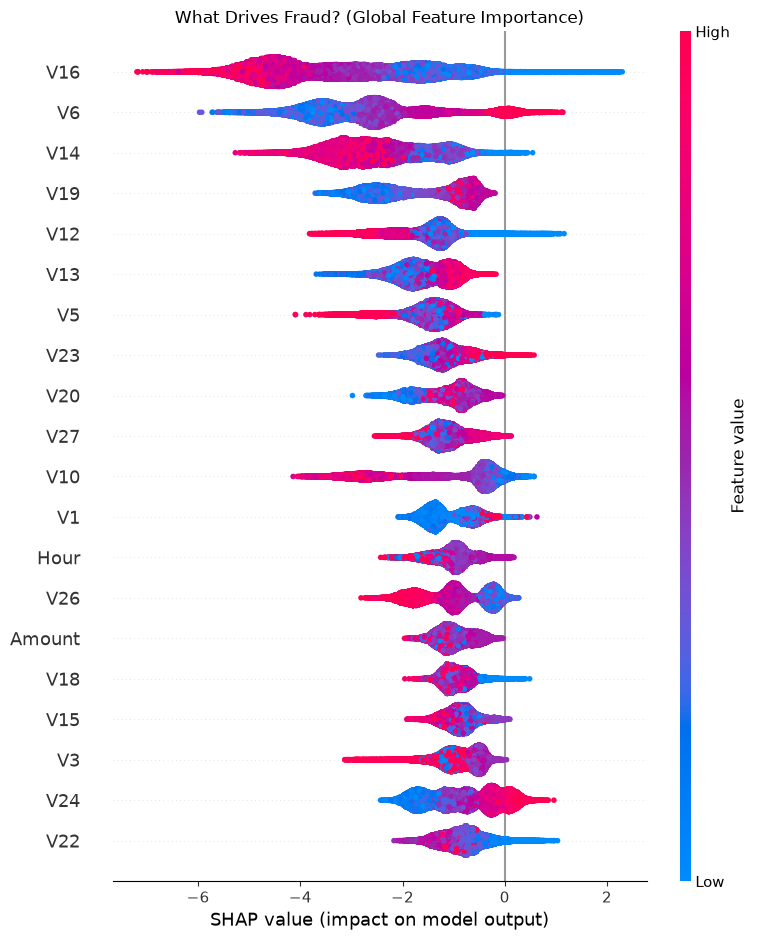

In [83]:
plt.title("What Drives Fraud? (Global Feature Importance)")
shap.summary_plot(shap_values, X_test_scaled, feature_names=X_test.columns)

In [84]:
import json
import os

In [85]:
cm = confusion_matrix(y_test, final_test_predictions)

metrics_dict = {
    'FINAL_PR_AUC': float(average_precision_score(y_test, final_test_probabilities)),
    'FINAL_ROC_AUC': float(roc_auc_score(y_test, final_test_probabilities)),
    'FINAL_PRECISION': float(precision_score(y_test, final_test_predictions)),
    'FINAL_RECALL': float(recall_score(y_test, final_test_predictions)),
    'FINAL_F1': float(f1_score(y_test, final_test_predictions)),
    'FINAL_TN': int(cm[0, 0]),
    'FINAL_FP': int(cm[0, 1]),
    'FINAL_FN': int(cm[1, 0]),
    'FINAL_TP': int(cm[1, 1])
}

In [86]:
#save it next to the model files
os.makedirs("model_artifacts", exist_ok=True)
with open("model_artifacts/metrics.json", "w") as f:
    json.dump(metrics_dict, f, indent=4)

print("Metrics saved to metrics.json! The Streamlit app is now perfectly synced.")

Metrics saved to metrics.json! The Streamlit app is now perfectly synced.
